Generando gráficas comparativas de:
   • Train: train_train_metrics.csv
   • Val:   train_validation_metrics.csv



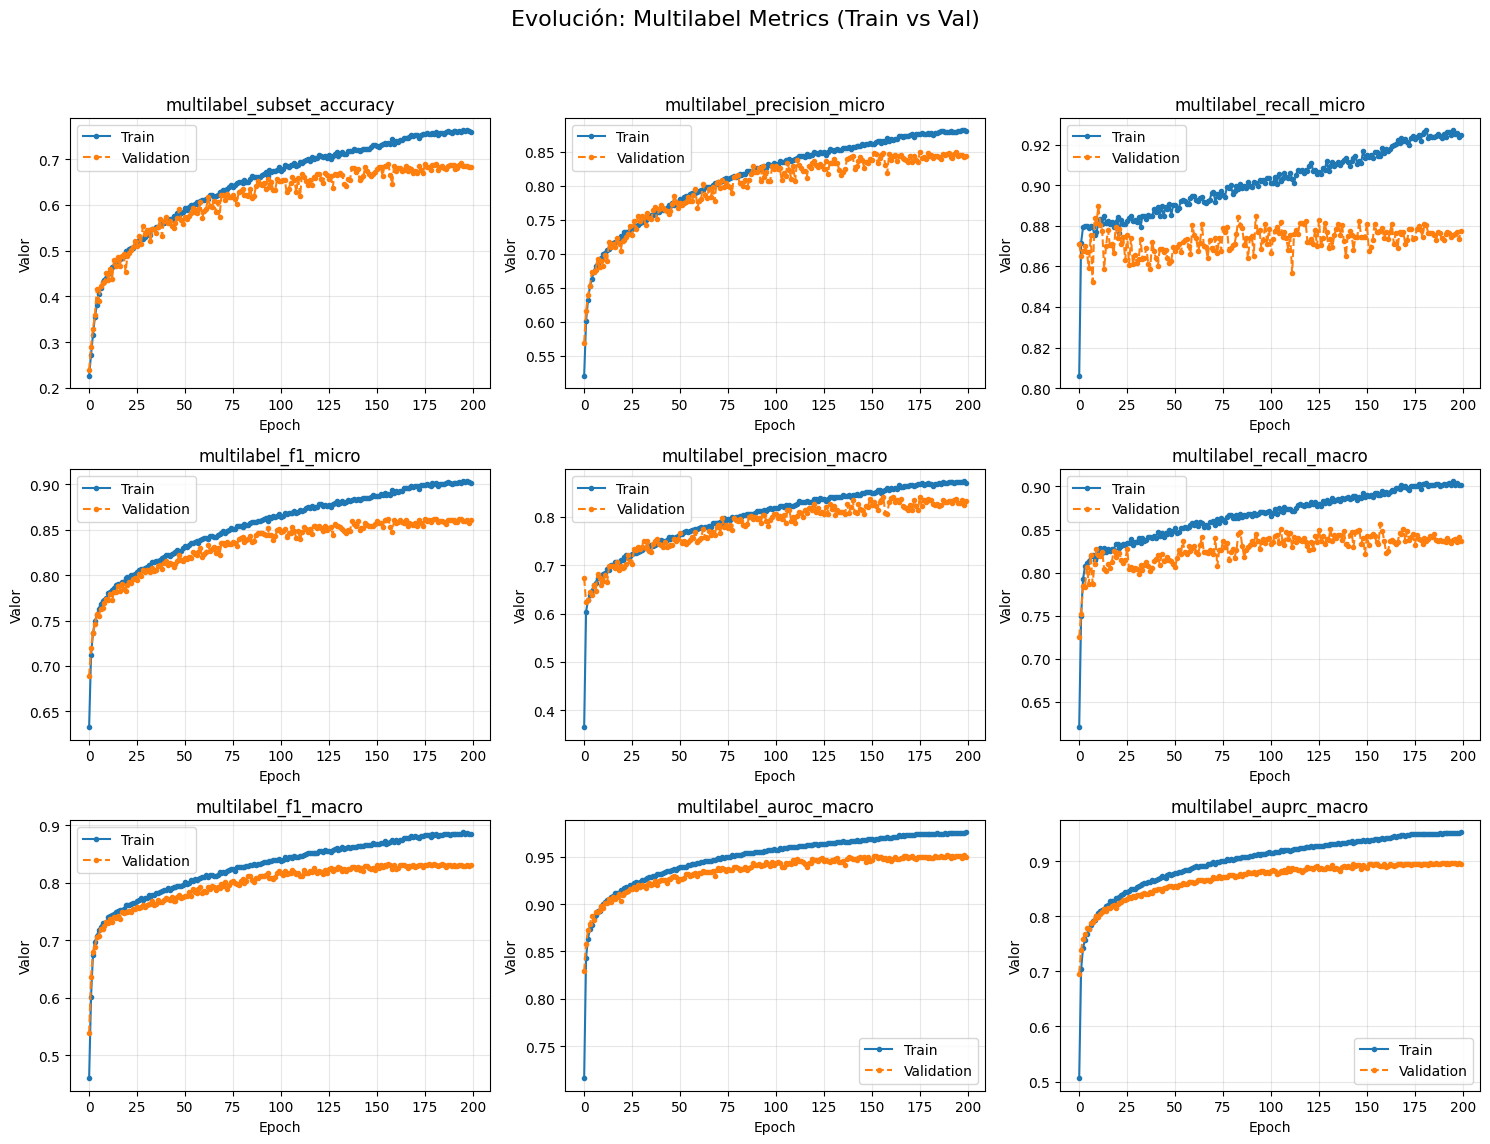

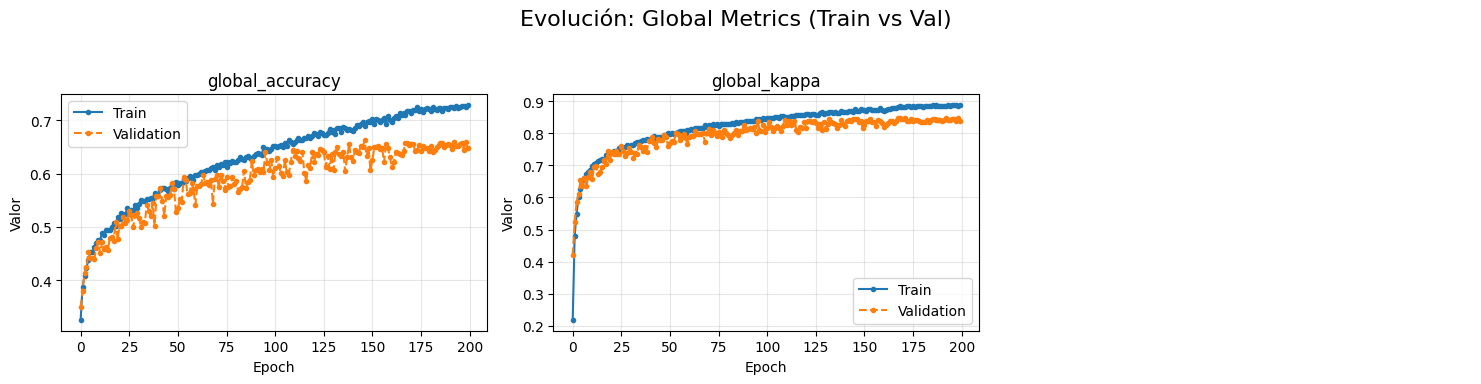

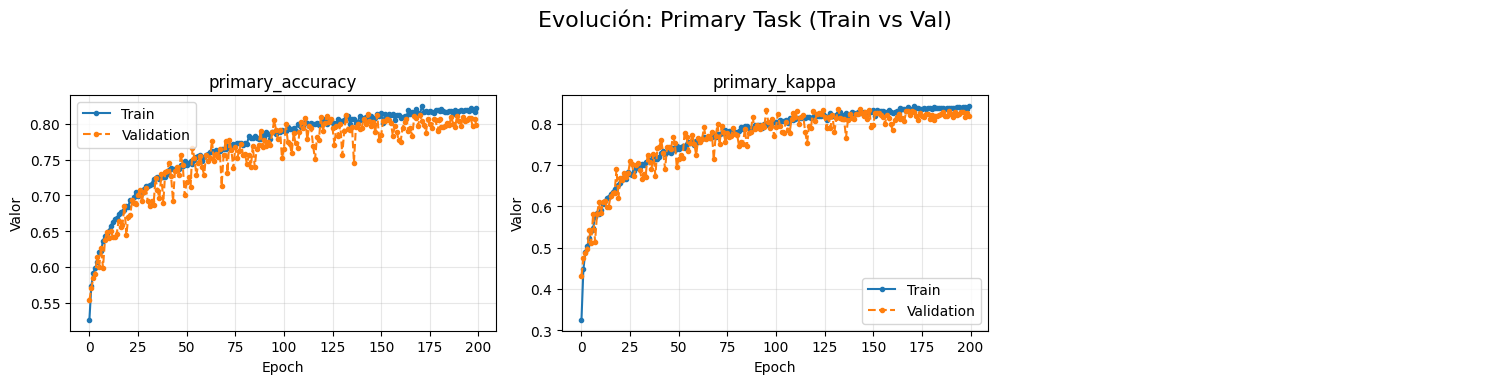

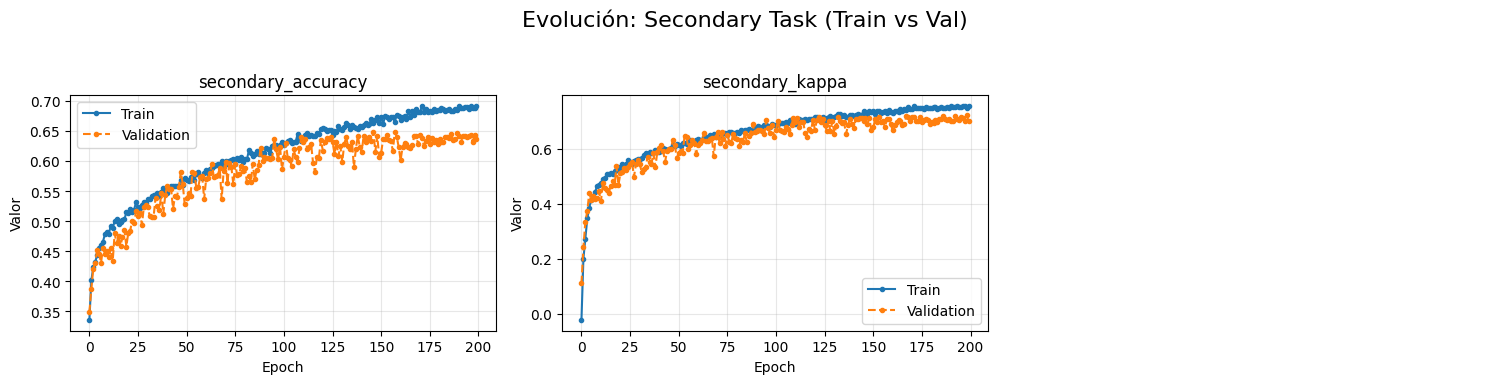


RESULTADOS FINALES EN DATASETS DE PRUEBA

------------------------------------------------------------
  TEST INTERNO (TRAIN TEST)
    Archivo: train_test_metrics.csv
------------------------------------------------------------

GLOBAL METRICS
Metrica                             | Valor     
--------------------------------------------------
  • Accuracy                        : 0.7625
  • Precision Micro                 : 0.7625
  • Precision Macro                 : 0.7734
  • Precision Weighted              : 0.7664
  • Recall Micro                    : 0.7625
  • Recall Macro                    : 0.7100
  • Recall Weighted                 : 0.7625
  • F1 Micro                        : 0.7625
  • F1 Macro                        : 0.7350
  • F1 Weighted                     : 0.7631
  • Kappa                           : 0.8961

PRIMARY TASK
Metrica                             | Valor     
--------------------------------------------------
  • Accuracy                        : 0.8361
 

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import math

def mostrar_resultados_test(ruta_carpeta, nombre_archivo, titulo):
    if not nombre_archivo:
        print(f"\n No se encontró archivo para: {titulo}")
        return

    ruta = os.path.join(ruta_carpeta, nombre_archivo)
    
    try:
        df = pd.read_csv(ruta)
        
        # Nos quedamos con la última fila (resultados finales)
        datos = df.iloc[-1]
        
        print("\n" + "-"*60)
        print(f"  {titulo.upper()}")
        print(f"    Archivo: {nombre_archivo}")
        print("-"*60)

        # Definimos las categorías basándonos en los prefijos de las columnas
        categorias = {
            "GLOBAL METRICS": "global_",
            "PRIMARY TASK": "primary_",
            "SECONDARY TASK": "secondary_",
            "MULTILABEL METRICS": "multilabel_"
        }

        # Iteramos por cada categoría para imprimir ordenadamente
        for nombre_cat, prefijo in categorias.items():
            # Filtramos las métricas que empiezan por el prefijo actual
            metricas_grupo = [k for k in datos.index if k.startswith(prefijo)]
            
            if metricas_grupo:
                print(f"\n{nombre_cat}")
                print(f"{'Metrica':<35} | {'Valor':<10}")
                print("-" * 50)
                
                for key in metricas_grupo:
                    valor = datos[key]
                    # Limpiamos el nombre: quitamos el prefijo y ponemos mayúsculas bonitas
                    nombre_limpio = key.replace(prefijo, "").replace("_", " ").title()
                    
                    # Formateo condicional: si es float lo mostramos con 4 decimales
                    if isinstance(valor, (float, int)):
                        val_str = f"{valor:.4f}"
                    else:
                        val_str = str(valor)
                        
                    print(f"  • {nombre_limpio:<31} : {val_str}")

        print("\n" + "═"*60 + "\n")

    except Exception as e:
        print(f"Error leyendo {nombre_archivo}: {e}")

def analizar_entrenamiento_y_test(ruta_carpeta):
    if not os.path.exists(ruta_carpeta):
        print(f"La ruta '{ruta_carpeta}' no existe.")
        return

    archivos = [f for f in os.listdir(ruta_carpeta) if f.endswith('.csv')]
    
    # 1. Identificar los archivos por nombre
    f_train = next((f for f in archivos if "train_train" in f), None)
    f_val   = next((f for f in archivos if "train_validation" in f), None)
    f_test  = next((f for f in archivos if "train_test" in f), None)
    f_sicap = next((f for f in archivos if "sicap_test" in f), None)

    # --- PARTE 1: GRÁFICAS EVOLUTIVAS (Train vs Validation) ---
    if f_train and f_val:
        print(f"Generando gráficas comparativas de:")
        print(f"   • Train: {f_train}")
        print(f"   • Val:   {f_val}\n")
        
        df_t = pd.read_csv(os.path.join(ruta_carpeta, f_train)).sort_values('epoch')
        df_v = pd.read_csv(os.path.join(ruta_carpeta, f_val)).sort_values('epoch')
        
        # Definir grupos de métricas para organizar las gráficas
        grupos_metricas = {
            "Multilabel Metrics": ['multilabel_subset_accuracy', 'multilabel_precision_micro', 'multilabel_recall_micro', 
                                   'multilabel_f1_micro', 'multilabel_precision_macro', 'multilabel_recall_macro', 
                                   'multilabel_f1_macro', 'multilabel_auroc_macro', 'multilabel_auprc_macro'],
            "Global Metrics": ['global_accuracy', 'global_precision', 'global_recall', 'global_f1', 'global_kappa'],
            "Primary Task": ['primary_accuracy', 'primary_precision', 'primary_recall', 'primary_f1', 'primary_kappa'],
            "Secondary Task": ['secondary_accuracy', 'secondary_precision', 'secondary_recall', 'secondary_f1', 'secondary_kappa'],
            
        }

        for nombre_grupo, columnas in grupos_metricas.items():
            # Filtrar columnas que realmente existen en el CSV
            cols_existentes = [c for c in columnas if c in df_t.columns and c in df_v.columns]
            
            if not cols_existentes:
                continue

            # Configuración de subplots (calculamos filas necesarias)
            n_cols = 3
            n_rows = math.ceil(len(cols_existentes) / n_cols)
            fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))
            fig.suptitle(f'Evolución: {nombre_grupo} (Train vs Val)', fontsize=16)
            axes = axes.flatten()

            for i, col in enumerate(cols_existentes):
                ax = axes[i]
                ax.plot(df_t['epoch'], df_t[col], label='Train', marker='.', linestyle='-')
                ax.plot(df_v['epoch'], df_v[col], label='Validation', marker='.', linestyle='--')
                
                ax.set_title(col)
                ax.set_xlabel('Epoch')
                ax.set_ylabel('Valor')
                ax.legend()
                ax.grid(True, alpha=0.3)

            # Ocultar subplots vacíos si los hay
            for j in range(i + 1, len(axes)):
                axes[j].axis('off')

            plt.tight_layout(rect=[0, 0.03, 1, 0.95])
            plt.show()
    else:
        print("No se encontraron los archivos 'train_train' y 'train_validation' para graficar.")

    # --- PARTE 2: RESULTADOS FINALES (Test y Sicap) ---
    print("\n" + "="*80)
    print("RESULTADOS FINALES EN DATASETS DE PRUEBA")
    print("="*80)

    mostrar_resultados_test(ruta_carpeta, f_test, "TEST INTERNO (Train Test)")
    mostrar_resultados_test(ruta_carpeta, f_sicap, "TEST EXTERNO (SICAP)")

# --- EJECUCIÓN ---
analizar_entrenamiento_y_test("/workspace/results/20260109_212740_model-KEEP_frozen_graph_alphape-0_alphapc-0_AdamW_lrate-1e-05_wdecay-1e-05_batch_size-32_epochs-200")

In [2]:
import os
import pandas as pd
import glob

def parsear_nombre_carpeta(nombre_carpeta):
    """
    Intenta extraer parámetros del nombre de la carpeta (ej: lrate-0.0001)
    para crear columnas limpias.
    """
    info = {}
    parts = nombre_carpeta.split('_')
    
    # Intentamos extraer fecha y hora
    if len(parts) >= 2:
        info['ID_Date'] = parts[0]
        info['ID_Time'] = parts[1]
    
    # Extraemos pares clave-valor si existen (ej: lrate-0.001)
    for part in parts:
        if '-' in part:
            try:
                key, val = part.split('-', 1)
                # Convertir a numero si es posible
                try:
                    val = float(val)
                except ValueError:
                    pass
                info[key] = val
            except:
                continue
    
    # Si no pudo extraer nada útil, devolvemos el nombre completo
    if len(info) < 3:
        return {'Experiment_Name': nombre_carpeta}
    
    return info

def obtener_metricas_archivo(ruta_archivo, prefijo_columna):
    """
    Lee la última fila del CSV y renombra las columnas con un prefijo 
    (ej: TEST_ o SICAP_)
    """
    try:
        df = pd.read_csv(ruta_archivo)
        # Tomamos la última época/fila
        ultima_fila = df.iloc[-1].to_dict()
        
        # Filtramos columnas que no sean metricas útiles (ej: epoch)
        metricas_limpias = {}
        for k, v in ultima_fila.items():
            if 'epoch' in k:
                continue
                
            # Limpieza de nombre: 'global_accuracy' -> 'Global Accuracy'
            nombre_base = k.replace('_', ' ').title()
            
            # Nuevo nombre: TEST - Global Accuracy
            nuevo_nombre = f"{prefijo_columna} - {nombre_base}"
            metricas_limpias[nuevo_nombre] = v
            
        return metricas_limpias
    except Exception as e:
        print(f"  [!] Error leyendo {os.path.basename(ruta_archivo)}: {e}")
        return {}

def generar_tabla_comparativa(lista_rutas):
    """
    Toma una lista de rutas y genera un DataFrame pandas comparativo.
    """
    datos_todos = []

    print(f"Procesando {len(lista_rutas)} experimentos...")

    for ruta in lista_rutas:
        if not os.path.exists(ruta):
            print(f"  [x] Ruta no existe: {ruta}")
            continue

        nombre_carpeta = os.path.basename(os.path.normpath(ruta))
        
        # 1. Obtener hiperparámetros del nombre
        fila_datos = parsear_nombre_carpeta(nombre_carpeta)
        
        # 2. Buscar archivos
        archivos = os.listdir(ruta)
        f_test = next((f for f in archivos if "train_test" in f and f.endswith('.csv')), None)
        f_sicap = next((f for f in archivos if "sicap_test" in f and f.endswith('.csv')), None)

        # 3. Leer métricas Test Interno
        if f_test:
            metricas_test = obtener_metricas_archivo(os.path.join(ruta, f_test), "INTERNAL")
            fila_datos.update(metricas_test)
        else:
            fila_datos['INTERNAL - Status'] = 'Not Found'

        # 4. Leer métricas SICAP
        if f_sicap:
            metricas_sicap = obtener_metricas_archivo(os.path.join(ruta, f_sicap), "SICAP")
            fila_datos.update(metricas_sicap)
        else:
            fila_datos['SICAP - Status'] = 'Not Found'
            
        datos_todos.append(fila_datos)

    # Crear DataFrame
    df_res = pd.DataFrame(datos_todos)

    # Reordenar columnas: Poner los hiperparámetros primero
    cols = list(df_res.columns)
    # Identificamos columnas de métricas (contienen " - ")
    cols_metricas = [c for c in cols if " - " in c]
    cols_params = [c for c in cols if c not in cols_metricas]
    
    # Ordenar métricas alfabéticamente para agrupar Global, Primary, etc.
    cols_metricas.sort()
    
    df_final = df_res[cols_params + cols_metricas]
    
    return df_final
def generar_tabla_comparativa_red(lista_rutas):
    """
    Toma una lista de rutas y genera:
    - DataFrame completo (todas las métricas)
    - DataFrame reducido (sin métricas macro y micro)
    """
    datos_todos = []

    print(f"Procesando {len(lista_rutas)} experimentos...")

    for ruta in lista_rutas:
        if not os.path.exists(ruta):
            print(f"  [x] Ruta no existe: {ruta}")
            continue

        nombre_carpeta = os.path.basename(os.path.normpath(ruta))
        
        # 1. Obtener hiperparámetros del nombre
        fila_datos = parsear_nombre_carpeta(nombre_carpeta)
        
        # 2. Buscar archivos
        archivos = os.listdir(ruta)
        f_test = next((f for f in archivos if "train_test" in f and f.endswith('.csv')), None)
        f_sicap = next((f for f in archivos if "sicap_test" in f and f.endswith('.csv')), None)

        # 3. Leer métricas Test Interno
        if f_test:
            metricas_test = obtener_metricas_archivo(
                os.path.join(ruta, f_test), "INTERNAL"
            )
            fila_datos.update(metricas_test)
        else:
            fila_datos['INTERNAL - Status'] = 'Not Found'

        # 4. Leer métricas SICAP
        if f_sicap:
            metricas_sicap = obtener_metricas_archivo(
                os.path.join(ruta, f_sicap), "SICAP"
            )
            fila_datos.update(metricas_sicap)
        else:
            fila_datos['SICAP - Status'] = 'Not Found'
            
        datos_todos.append(fila_datos)

    # ---------------------------
    # DataFrame completo
    # ---------------------------
    df_res = pd.DataFrame(datos_todos)

    cols = list(df_res.columns)
    cols_metricas = [c for c in cols if " - " in c]
    cols_params = [c for c in cols if c not in cols_metricas]

    cols_metricas.sort()
    df_completo = df_res[cols_params + cols_metricas]

    # ---------------------------
    # DataFrame reducido
    # (sin macro ni micro métricas)
    # ---------------------------
    cols_metricas_reducidas = [
        c for c in cols_metricas
        if not any(x in c.lower() for x in ['macro', 'micro'])
    ]

    df_reducido = df_res[cols_params + cols_metricas_reducidas]

    return df_completo, df_reducido

def estilizar_tabla(df):
    """
    Aplica estilo condicional (heatmap) para resaltar valores altos/bajos
    en Jupyter Notebooks.
    """
    # Seleccionamos solo columnas numéricas para el gradiente
    cols_numericas = df.select_dtypes(include=['float64', 'int']).columns
    
    # Definimos un formateador para reducir decimales
    format_dict = {col: "{:.4f}" for col in cols_numericas}
    
    return df.style.background_gradient(cmap='RdYlGn', subset=cols_numericas)\
                   .format(format_dict)\
                   .set_properties(**{'border': '1px solid black', 'text-align': 'center'})\
                   .set_table_styles([
                       {'selector': 'th', 'props': [('font-size', '10pt'), ('text-align', 'center'), ('background-color', '#f2f2f2')]}
                   ])

# ==============================================================================
# EJEMPLO DE USO
# ==============================================================================

# 1. Define tu lista de rutas (puedes usar glob para obtenerlas automáticamente)
experimentos = [
    r"/workspace/results/20260108_150716_model-CNN_frozen_graph_alphape-0_alphapc-0_AdamW_lrate-1e-05_wdecay-1e-05_batch_size-32_epochs-200",
    r"/workspace/results/20260109_212740_model-KEEP_frozen_graph_alphape-0_alphapc-0_AdamW_lrate-1e-05_wdecay-1e-05_batch_size-32_epochs-200",
    r"/workspace/results/20260124_123242_model-KEEP_frozen_mlp_alphape-0_alphapc-0_AdamW_lrate-1e-05_wdecay-1e-05_batch_size-64_epochs-100",
]

# O usar glob para coger todas las carpetas en results:
# import glob
# experimentos = glob.glob("/workspace/results/*")

# 2. Generar el DataFrame
df_resultados, df_reducido = generar_tabla_comparativa_red(experimentos)

# 3. Mostrar resultados
print("Tabla generada con éxito. Mostrando las primeras filas:")
estilizar_tabla(df_resultados)

print("-")
estilizar_tabla(df_reducido)

Procesando 3 experimentos...
Tabla generada con éxito. Mostrando las primeras filas:
-


,ID_Date,ID_Time,model,alphape,alphapc,lrate,wdecay,size,epochs,INTERNAL - Global Accuracy,INTERNAL - Global F1 Weighted,INTERNAL - Global Kappa,INTERNAL - Global Precision Weighted,INTERNAL - Global Recall Weighted,INTERNAL - Multilabel Auprc Weighted,INTERNAL - Multilabel Auroc Weighted,INTERNAL - Multilabel F1 Weighted,INTERNAL - Multilabel Precision Weighted,INTERNAL - Multilabel Recall Weighted,INTERNAL - Multilabel Subset Accuracy,INTERNAL - Primary Accuracy,INTERNAL - Primary F1 Weighted,INTERNAL - Primary Kappa,INTERNAL - Primary Precision Weighted,INTERNAL - Primary Recall Weighted,INTERNAL - Secondary Accuracy,INTERNAL - Secondary F1 Weighted,INTERNAL - Secondary Kappa,INTERNAL - Secondary Precision Weighted,INTERNAL - Secondary Recall Weighted,SICAP - Global Accuracy,SICAP - Global F1 Weighted,SICAP - Global Kappa,SICAP - Global Precision Weighted,SICAP - Global Recall Weighted,SICAP - Multilabel Auprc Weighted,SICAP - Multilabel Auroc Weighted,SICAP - Multilabel F1 Weighted,SICAP - Multilabel Precision Weighted,SICAP - Multilabel Recall Weighted,SICAP - Multilabel Subset Accuracy,SICAP - Primary Accuracy,SICAP - Primary F1 Weighted,SICAP - Primary Kappa,SICAP - Primary Precision Weighted,SICAP - Primary Recall Weighted,SICAP - Secondary Accuracy,SICAP - Secondary F1 Weighted,SICAP - Secondary Kappa,SICAP - Secondary Precision Weighted,SICAP - Secondary Recall Weighted,SICAP - Status
0,20260108,150716,CNN,0.0000,0.0000,0.0000,0.0000,32.0000,200.0000,0.7007,0.6955,0.8555,0.6922,0.7007,0.9091,0.9340,0.8463,0.7981,0.9040,0.6591,0.7767,0.7760,0.7966,0.7764,0.7767,0.6235,0.6222,0.7091,0.6239,0.6235,0.3596,0.3042,0.3542,0.2788,0.3596,0.7112,0.7684,0.5766,0.4822,0.7207,0.4123,0.5219,0.4346,0.3118,0.3799,0.5219,0.3596,0.3051,0.1996,0.2651,0.3596,nan
1,20260109,212740,KEEP,0.0000,0.0000,0.0000,0.0000,32.0000,200.0000,0.7625,0.7631,0.8961,0.7664,0.7625,0.9487,0.9587,0.8761,0.8309,0.9278,0.7019,0.8361,0.8361,0.8577,0.8381,0.8361,0.6936,0.6959,0.7729,0.7067,0.6936,0.5800,0.5951,0.7211,0.7610,0.5800,0.8803,0.9033,0.7739,0.7706,0.8289,0.5800,0.6200,0.6343,0.6777,0.8259,0.6200,0.4600,0.4597,0.5057,0.6117,0.4600,nan
2,20260124,123242,KEEP,0.0000,0.0000,0.0000,0.0000,64.0000,100.0000,0.6152,0.5909,0.7401,0.6335,0.6152,0.9036,0.9263,0.8224,0.7895,0.8658,0.5998,0.7435,0.7341,0.7467,0.7416,0.7435,0.5748,0.5623,0.6041,0.5650,0.5748,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,nan,Not Found


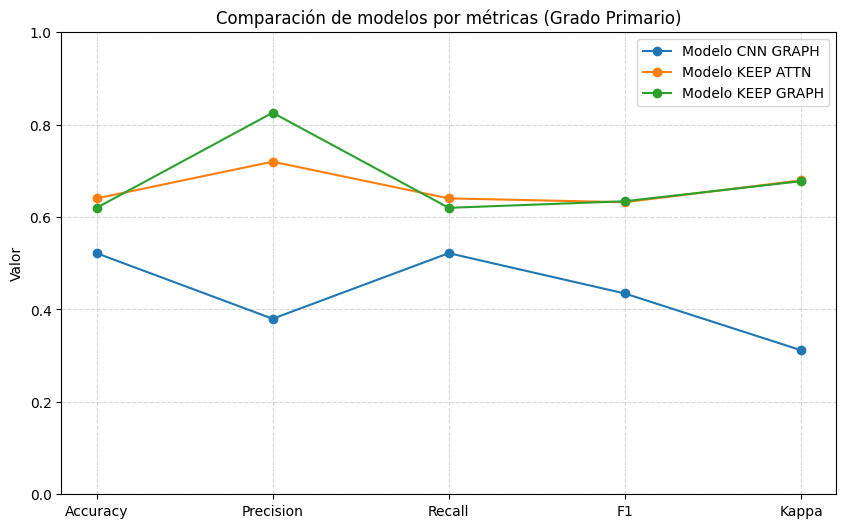

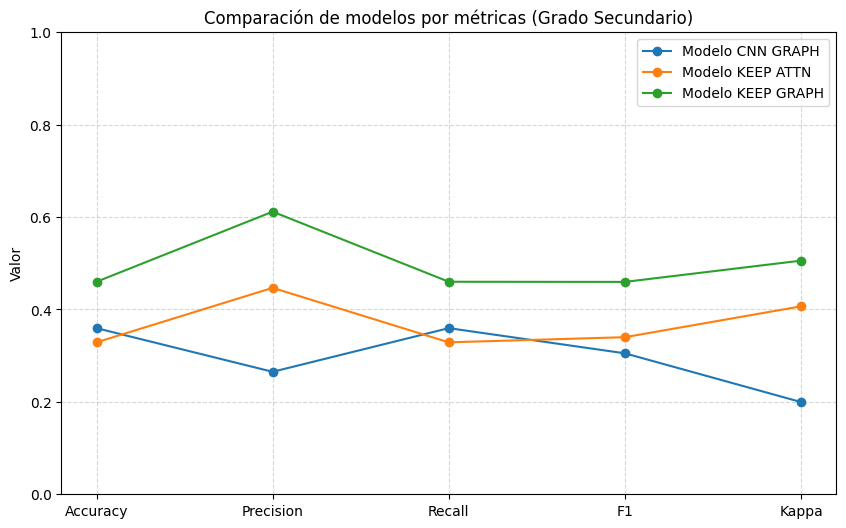

In [1]:
import matplotlib.pyplot as plt
import numpy as np

def graficos_comp_mdl(valores_modelos, label="Primario"):
    """
    Genera gráficos comparativos de modelos basados en métricas específicas.
    """
    # Definir las métricas
    metricas = ['Accuracy', 'Precision', 'Recall', 'F1', 'Kappa']

    # Valores por modelo (puedes cambiar estos datos)
    # Cada lista interna corresponde a los valores de las métricas en el mismo orden
    

    # Convertir las métricas a posiciones en el eje X
    x = np.arange(len(metricas))

    # Crear la figura
    plt.figure(figsize=(10, 6))

    # Dibujar una línea de puntos por cada modelo
    for modelo, valores in valores_modelos.items():
        plt.plot(x, valores, marker='o', linestyle='-', label=modelo)

    # Configurar el eje X con los nombres de las métricas
    plt.xticks(x, metricas)

    # Etiquetas y título
    plt.ylabel('Valor')
    plt.title(f"Comparación de modelos por métricas (Grado {label})")
    plt.ylim(0, 1)  # Suponiendo que los valores van de 0 a 1
    plt.grid(True, linestyle='--', alpha=0.5)

    # Leyenda
    plt.legend()

    # Mostrar la gráfica
    plt.show()

valores_modelos_primary = {
        'Modelo CNN GRAPH': [0.5219, 0.3799, 0.5219, 0.4346, 0.3118],
        'Modelo KEEP ATTN': [0.6404,0.7199,0.6404,0.6322,0.6795],
        'Modelo KEEP GRAPH': [0.6200,0.8259,0.6200,0.6343,0.6777]

    }
graficos_comp_mdl(valores_modelos_primary, label="Primario")

valores_modelos = {
    'Modelo CNN GRAPH': [0.3596, 0.2651, 0.3596, 0.3051, 0.1996],
    'Modelo KEEP ATTN': [0.3289, 0.4468, 0.3289, 0.3400, 0.4068],
    'Modelo KEEP GRAPH': [0.4600, 0.6117, 0.4600, 0.4597, 0.5057]


}
graficos_comp_mdl(valores_modelos, label="Secundario")